In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)
print("First 5 rows:")
print(df.head())
print("\nDataset Information:")
print(df.info())
print(df.dtypes)
print("Missing values:")
print(df.isnull().sum())

Saving cricket_player_performance.csv to cricket_player_performance.csv
First 5 rows:
         Player         Team          Role  Matches  Innings  Runs  \
0  Virat Sharma    Australia   All-Rounder       18       16  1110   
1   Arjun Mehta  New Zealand        Bowler       22       19   337   
2   Rohan Singh  New Zealand  Wicketkeeper       23       23  1055   
3    Aman Verma      England  Wicketkeeper       28       25  1332   
4   Karan Patel        India  Wicketkeeper       14       14   896   

   Balls_Faced  Batting_Average  Strike_Rate  Wickets  Overs_Bowled  \
0         2554           100.91        43.46       42            86   
1          859            28.08        39.23       35            38   
2         1590            81.15        66.35       20            47   
3         1992           121.09        66.87       41            74   
4         1066            49.78        84.05        8            53   

   Runs_Conceded  Economy_Rate  Catches  
0            200        

In [2]:
df["Catches"] = df["Catches"].fillna(df["Catches"].median())
df["Economy_Rate"] = df["Economy_Rate"].fillna(df["Economy_Rate"].mean())
df["Batting_Average"] = df["Batting_Average"].fillna(df["Batting_Average"].mean())
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Player             0
Team               0
Role               0
Matches            0
Innings            0
Runs               0
Balls_Faced        0
Batting_Average    0
Strike_Rate        0
Wickets            0
Overs_Bowled       0
Runs_Conceded      0
Economy_Rate       0
Catches            0
dtype: int64


In [3]:
print("Runs Statistics")
print("Mean:", np.mean(df["Runs"]))
print("Median:", np.median(df["Runs"]))
print("Standard Deviation:", np.std(df["Runs"]))

print("\nStrike Rate Statistics")
print("Mean:", np.mean(df["Strike_Rate"]))
print("Median:", np.median(df["Strike_Rate"]))
print("Standard Deviation:", np.std(df["Strike_Rate"]))

print("\nWickets Statistics")
print("Mean:", np.mean(df["Wickets"]))
print("Median:", np.median(df["Wickets"]))
print("Standard Deviation:", np.std(df["Wickets"]))

Runs Statistics
Mean: 897.45
Median: 914.5
Standard Deviation: 327.3622572930484

Strike Rate Statistics
Mean: 53.8625
Median: 53.3
Standard Deviation: 13.281369611226093

Wickets Statistics
Mean: 24.7
Median: 24.0
Standard Deviation: 14.003928020380567


In [4]:
team_analysis = df.groupby("Team")[["Runs", "Wickets", "Catches"]].mean()
print(team_analysis)
role_analysis = df.groupby("Role")[["Runs", "Wickets", "Strike_Rate"]].mean()
print(role_analysis)
top_run_scorers = df.sort_values("Runs", ascending=False)
print(top_run_scorers[["Player", "Team", "Runs"]].head(10))

                    Runs    Wickets    Catches
Team                                          
Australia     819.000000  34.000000   9.000000
England       933.400000  23.800000  10.000000
India         834.000000  12.250000  15.250000
New Zealand   950.200000  29.000000  19.800000
South Africa  912.666667  26.333333  16.333333
                     Runs    Wickets  Strike_Rate
Role                                             
All-Rounder   1142.500000  24.000000      51.5575
Batsman        857.666667  32.333333      48.1550
Bowler         756.000000  20.500000      48.6225
Wicketkeeper   868.166667  20.333333      64.6000
          Player          Team  Runs
14   Aakash Jain   New Zealand  1433
3     Aman Verma       England  1332
11   Manav Joshi       England  1321
15   Kabir Sethi  South Africa  1301
13    Dev Kapoor   New Zealand  1113
0   Virat Sharma     Australia  1110
2    Rohan Singh   New Zealand  1055
5    Rahul Kumar  South Africa  1026
8    Nikhil Shah         India   969
1

In [5]:
top_wicket_takers = df.sort_values("Wickets", ascending=False)
print(top_wicket_takers[["Player", "Team", "Wickets"]].head(10))

            Player          Team  Wickets
15     Kabir Sethi  South Africa       43
9       Yash Gupta       England       43
0     Virat Sharma     Australia       42
3       Aman Verma       England       41
18      Ishaan Roy   New Zealand       38
1      Arjun Mehta   New Zealand       35
6       Aditya Rao     Australia       35
7       Vikram Das  South Africa       35
13      Dev Kapoor   New Zealand       31
12  Rishi Malhotra     Australia       25


In [1]:

plt.plot(df["Player"], df["Runs"], marker="o")
plt.xticks(rotation=45)
plt.xlabel("Player")
plt.ylabel("Runs")
plt.title("Runs Scored by Players")
plt.show()

NameError: name 'plt' is not defined

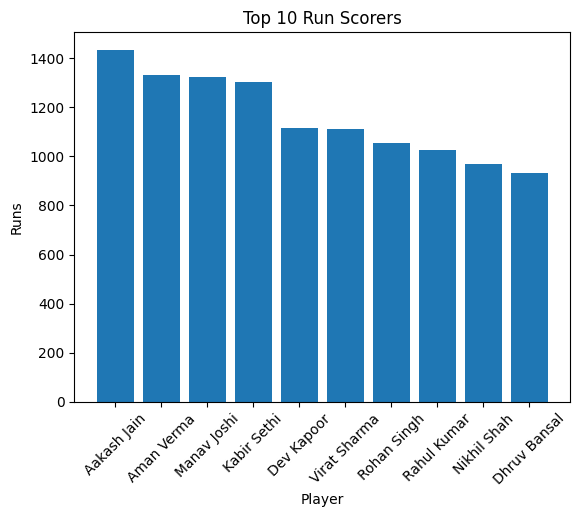

In [9]:
top10 = df.sort_values("Runs", ascending=False).head(10)
plt.bar(top10["Player"], top10["Runs"])

plt.xticks(rotation=45)
plt.xlabel("Player")
plt.ylabel("Runs")
plt.title("Top 10 Run Scorers")

plt.show()

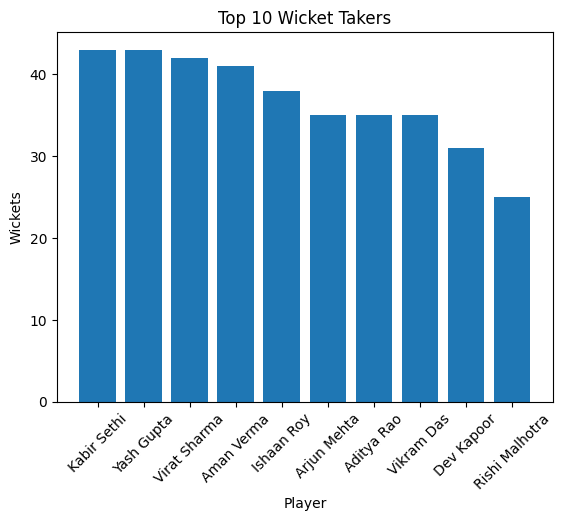

In [10]:
top10_wickets = df.sort_values("Wickets", ascending=False).head(10)
plt.bar(top10_wickets["Player"], top10_wickets["Wickets"])

plt.xticks(rotation=45)
plt.xlabel("Player")
plt.ylabel("Wickets")
plt.title("Top 10 Wicket Takers")
plt.show()

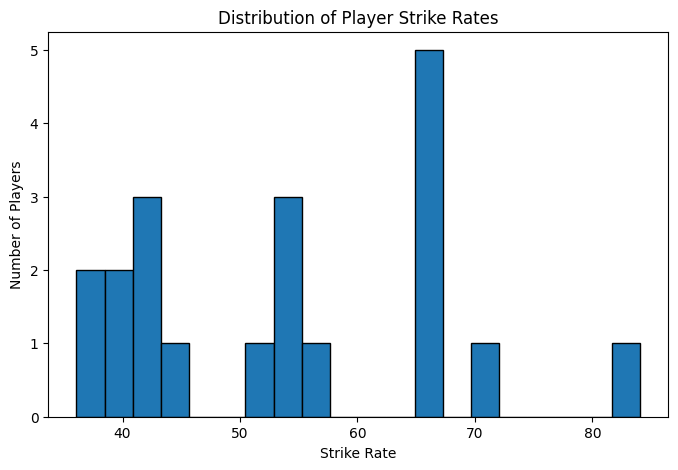

In [14]:
#Histogram — Strike Rate Distribution
plt.figure(figsize=(8, 5))
plt.hist(df["Strike_Rate"],bins=20,
    edgecolor='black')
plt.xlabel("Strike Rate")
plt.ylabel("Number of Players")
plt.title("Distribution of Player Strike Rates")
plt.show()

In [15]:
highest_runs = df.loc[df["Runs"].idxmax(), "Player"]
highest_wickets = df.loc[df["Wickets"].idxmax(), "Player"]
highest_strike_rate = df.loc[df["Strike_Rate"].idxmax(), "Player"]

print("CRICKET PERFORMANCE SUMMARY")
print("---------------------------")

print("Highest Run Scorer:", highest_runs)
print("Highest Wicket Taker:", highest_wickets)
print("Highest Strike Rate:", highest_strike_rate)
print("Average Runs:", round(df["Runs"].mean(), 2))
print("Average Wickets:", round(df["Wickets"].mean(), 2))

CRICKET PERFORMANCE SUMMARY
---------------------------
Highest Run Scorer: Aakash Jain
Highest Wicket Taker: Yash Gupta
Highest Strike Rate: Karan Patel
Average Runs: 897.45
Average Wickets: 24.7
